In [4]:
# Importing required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
# Loading the Cars24 dataset
dataset_url = "https://raw.githubusercontent.com/jatin5jan/CarPredict/main/cars_24_combined.csv"
df = pd.read_csv(dataset_url)
# Display first five records
df.head()

,Unnamed: 0,Car Name,Year,Distance,Owner,Fuel,Location,Drive,Type,Price
0,0,Maruti S PRESSO,2022.0,3878,1,PETROL,HR-98,Manual,HatchBack,514000
1,1,Hyundai Xcent,2018.0,32041,1,PETROL,TN-22,Manual,Sedan,674000
2,2,Tata Safari,2021.0,96339,1,DIESEL,TS-08,Automatic,SUV,1952000
3,3,Maruti Vitara Brezza,2019.0,51718,1,DIESEL,WB-24,Manual,SUV,690000
4,4,Tata Tiago,2021.0,19811,1,PETROL,HR-51,Manual,HatchBack,526000


In [6]:
# Checking dataset dimensions
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
print("Dataset Shape:", df.shape)

Number of Rows: 8015
Number of Columns: 10
Dataset Shape: (8015, 10)


In [7]:
# Displaying column names
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Unnamed: 0', 'Car Name', 'Year', 'Distance', 'Owner', 'Fuel', 'Location', 'Drive', 'Type', 'Price']


In [8]:
# Checking column names, non-null values and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8015 entries, 0 to 8014
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  8015 non-null   int64  
 1   Car Name    8014 non-null   object 
 2   Year        8014 non-null   float64
 3   Distance    8015 non-null   int64  
 4   Owner       8015 non-null   int64  
 5   Fuel        8015 non-null   object 
 6   Location    7802 non-null   object 
 7   Drive       8015 non-null   object 
 8   Type        8015 non-null   object 
 9   Price       8015 non-null   int64  
dtypes: float64(1), int64(4), object(5)
memory usage: 626.3+ KB


In [10]:
# Separating numerical and categorical variables
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(include=['object', 'category']).columns.tolist()
print("Numerical Columns:")
print(numerical_columns)
print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['Unnamed: 0', 'Year', 'Distance', 'Owner', 'Price']

Categorical Columns:
['Car Name', 'Fuel', 'Location', 'Drive', 'Type']


In [11]:
# Checking missing values in each column
missing_values = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})
missing_values = missing_values.sort_values(
    by='Missing Count', ascending=False
)
print("Missing Values Analysis:")
display(missing_values)

Missing Values Analysis:


,Missing Count,Missing Percentage
Location,213,2.657517
Car Name,1,0.012477
Year,1,0.012477
Unnamed: 0,0,0.000000
Distance,0,0.000000
Owner,0,0.000000
Fuel,0,0.000000
Drive,0,0.000000
Type,0,0.000000
Price,0,0.000000


In [12]:
# Checking duplicate records
duplicate_count = df.duplicated().sum()
print("Total Duplicate Records:", duplicate_count)
# Display duplicate records if present
if duplicate_count > 0:
    display(df[df.duplicated()])
else:
    print("No duplicate records found.")

Total Duplicate Records: 0
No duplicate records found.


In [13]:
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df)) * 100
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})
missing_summary = missing_summary[missing_summary['Missing Values'] > 0]
missing_summary

,Missing Values,Missing Percentage
Car Name,1,0.012477
Year,1,0.012477
Location,213,2.657517


In [15]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


In [19]:
df.describe(include='all')

,Unnamed: 0,Car Name,Year,Distance,Owner,Fuel,Location,Drive,Type,Price
count,8015.000000,8014,8014.000000,8015.000000,8015.000000,8015,7802,8015,8015,8.015000e+03
unique,NaN,126,NaN,NaN,NaN,4,436,2,5,NaN
top,NaN,Maruti Swift,NaN,NaN,NaN,PETROL,MH-12,Manual,HatchBack,NaN
freq,NaN,593,NaN,NaN,NaN,6413,286,6455,5080,NaN
mean,4007.000000,NaN,2016.995009,52621.411728,1.300187,NaN,NaN,NaN,NaN,5.748829e+05
std,2313.875537,NaN,2.861454,29182.922728,0.510893,NaN,NaN,NaN,NaN,2.651049e+05
min,0.000000,NaN,2010.000000,0.000000,1.000000,NaN,NaN,NaN,NaN,1.190000e+05
25%,2003.500000,NaN,2015.000000,30730.000000,1.000000,NaN,NaN,NaN,NaN,3.930000e+05
50%,4007.000000,NaN,2017.000000,50359.000000,1.000000,NaN,NaN,NaN,NaN,5.350000e+05
75%,6010.500000,NaN,2019.000000,71762.000000,2.000000,NaN,NaN,NaN,NaN,6.980000e+05


In [21]:
for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts())


Car Name:
Car Name
Maruti Swift          593
Hyundai Grand i10     451
Maruti Baleno         430
Hyundai Elite i20     382
Maruti Wagon R 1.0    362
                     ... 
Honda Accord            1
Toyota Camry            1
BMW 3 Series            1
Hyundai Sonata          1
Nissan Sunny            1
Name: count, Length: 126, dtype: int64

Fuel:
Fuel
PETROL    6413
DIESEL    1066
CNG        535
LPG          1
Name: count, dtype: int64

Location:
Location
MH-12    286
GJ-01    245
HR-26    228
KA-03    198
TS-07    189
        ... 
TS-27      1
HR-07      1
HR-27      1
TN-34      1
PB-46      1
Name: count, Length: 436, dtype: int64

Drive:
Drive
Manual       6455
Automatic    1560
Name: count, dtype: int64

Type:
Type
HatchBack    5080
Sedan        1622
SUV          1171
Lux_SUV        80
Lux_sedan      62
Name: count, dtype: int64


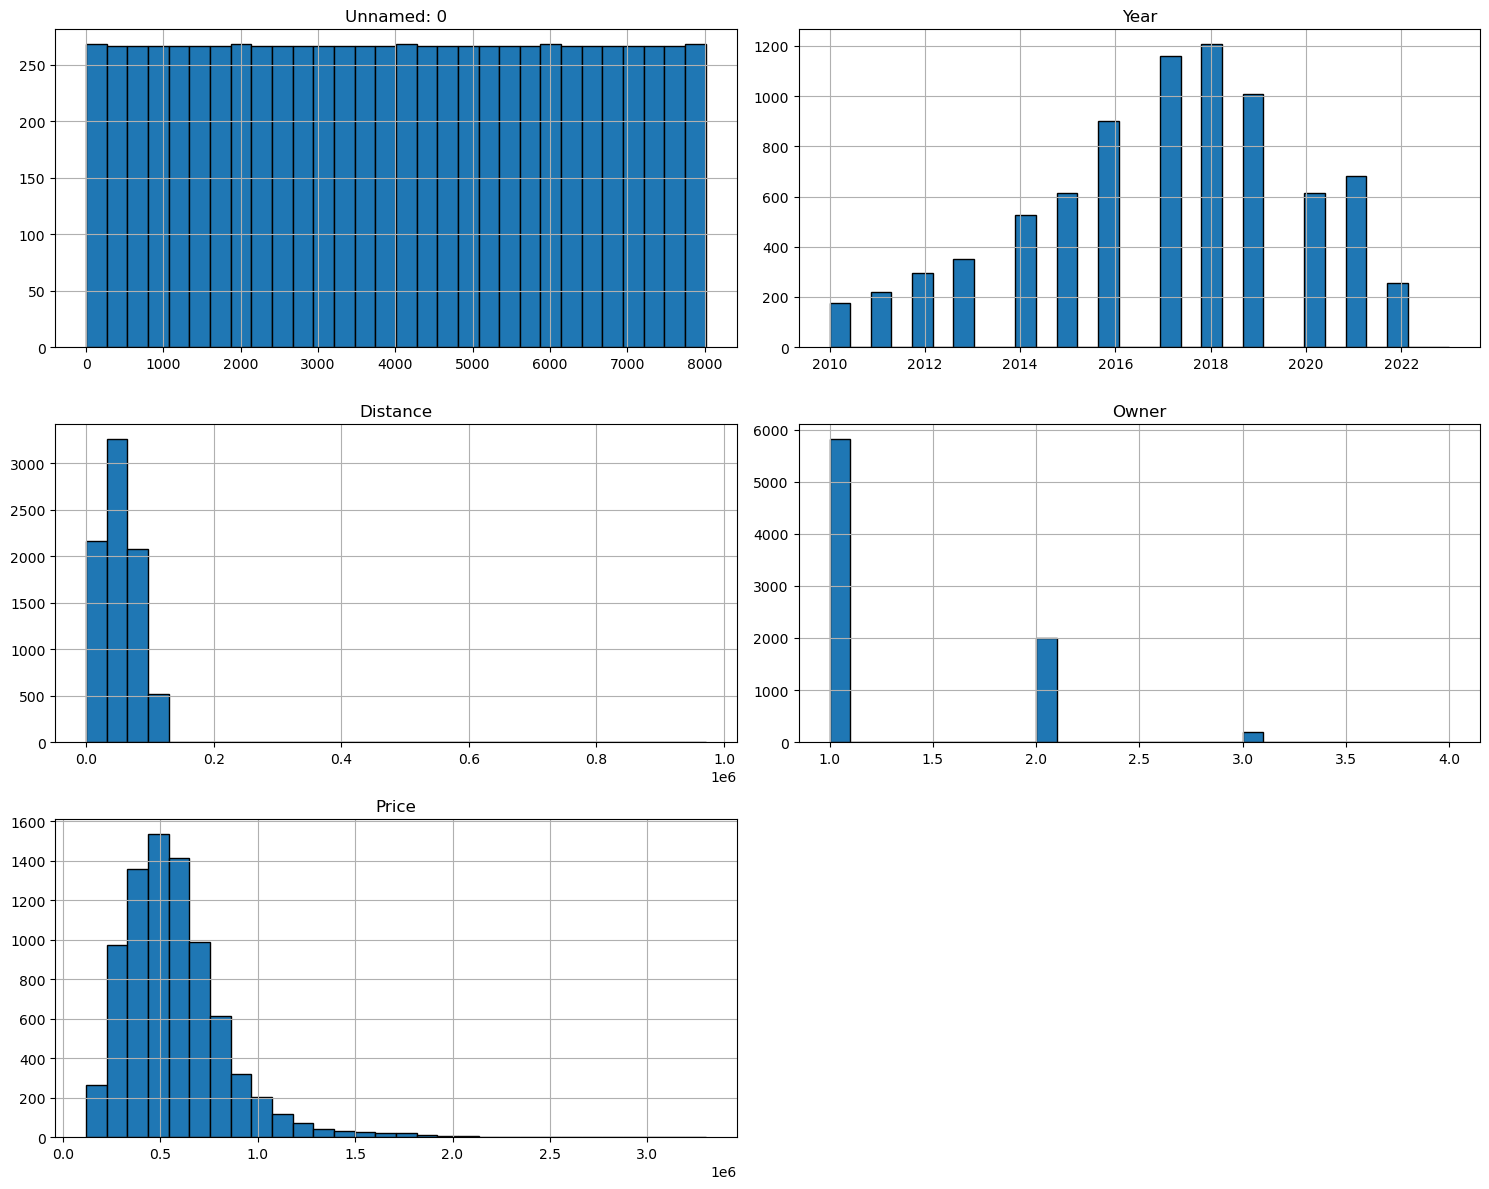

In [22]:
df.select_dtypes(include=['int64', 'float64']).hist(
    figsize=(15, 12),
    bins=30,
    edgecolor='black'
)
plt.tight_layout()
plt.show()

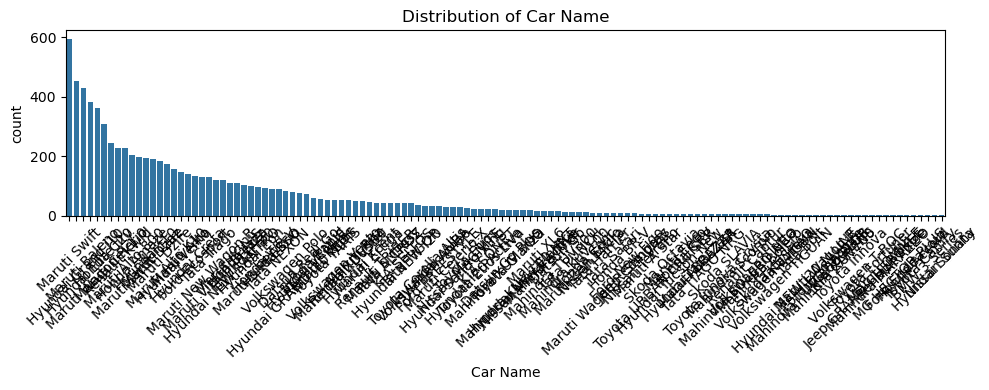

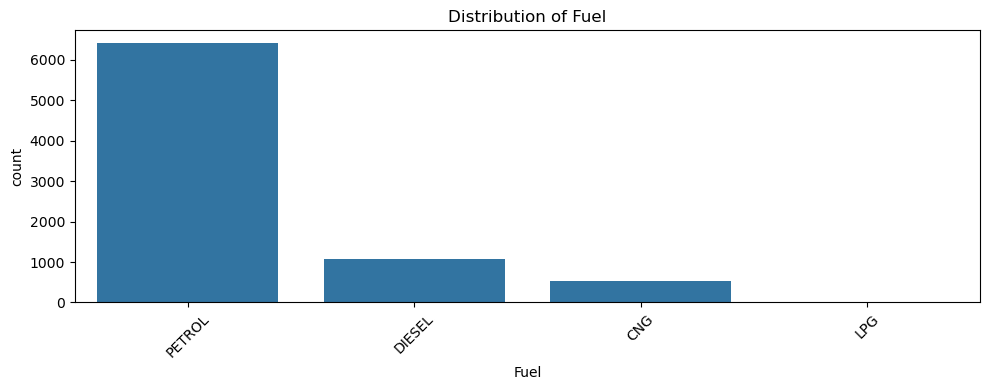

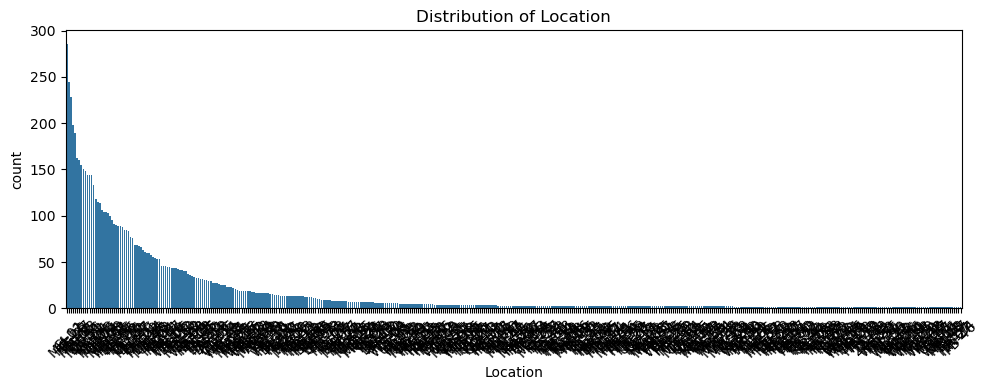

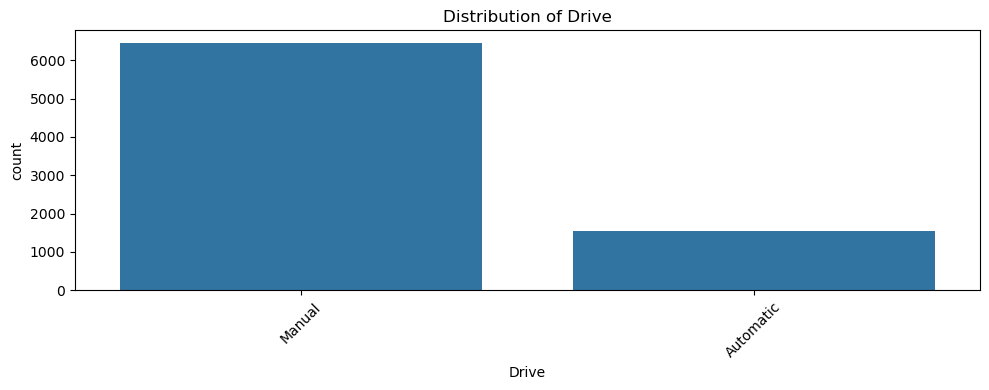

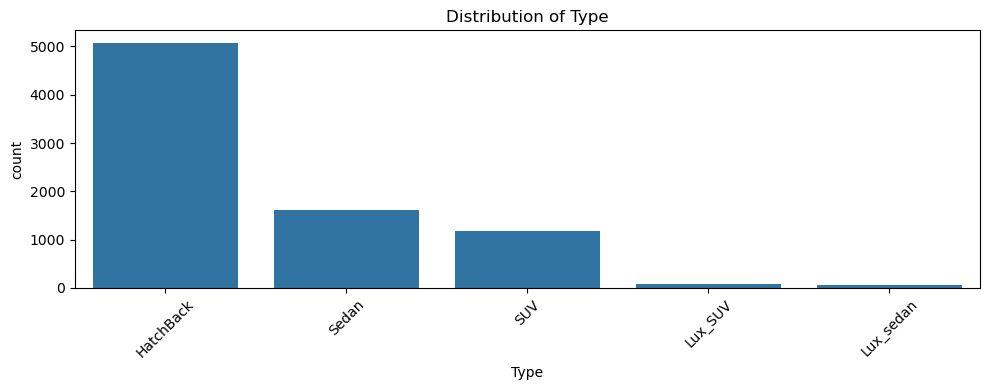

In [23]:
for col in categorical_columns:
    plt.figure(figsize=(10, 4))
    sns.countplot(data=df, x=col, order=df[col].value_counts().index)
    plt.title(f'Distribution of {col}')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

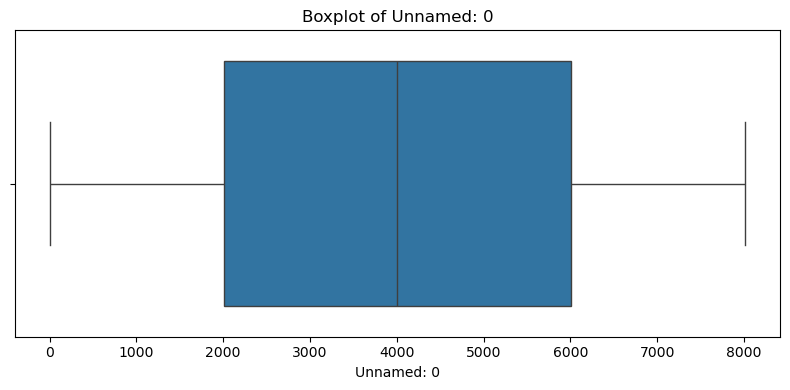

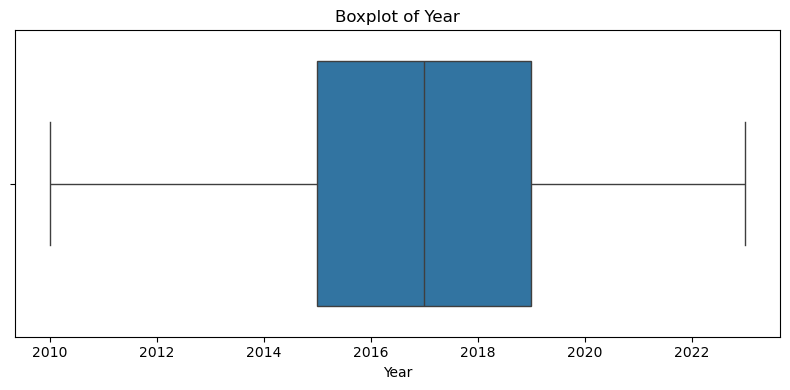

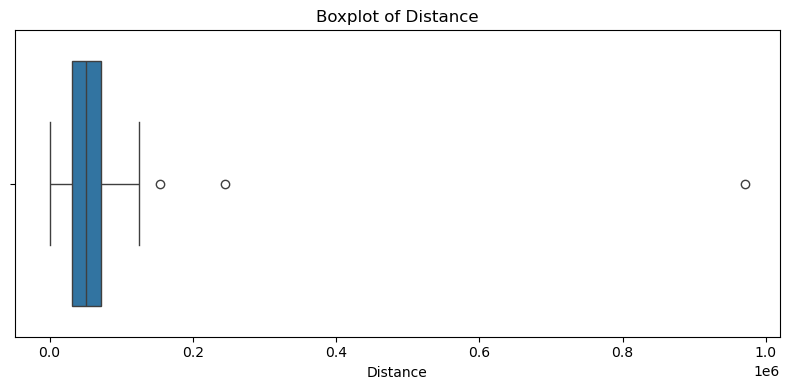

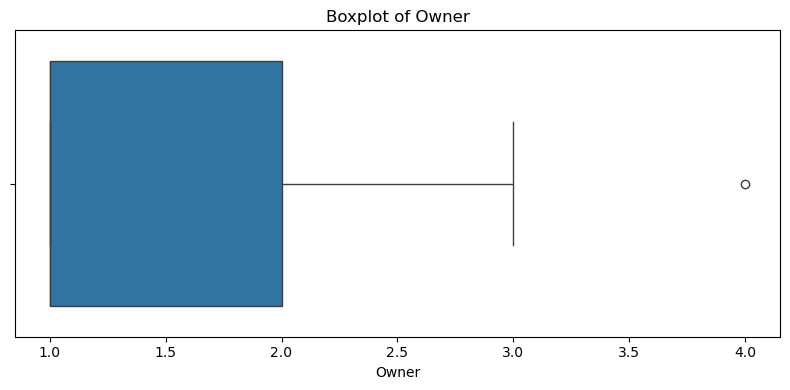

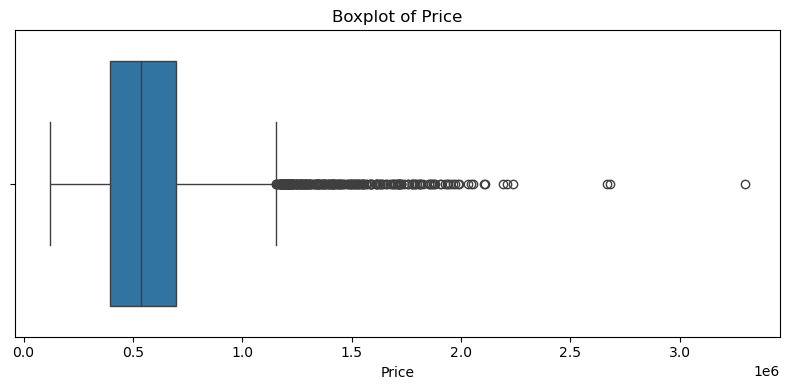

In [25]:
for col in numerical_columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.tight_layout()
    plt.show()

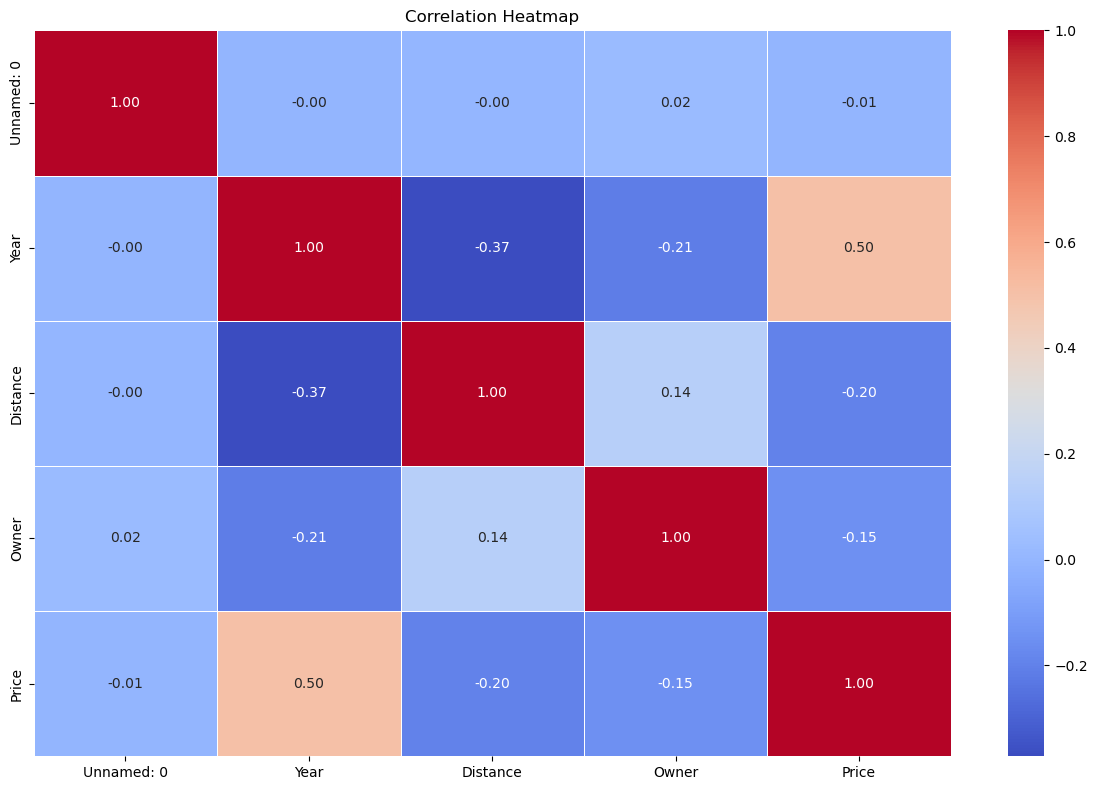

In [26]:
plt.figure(figsize=(12,8))
correlation = df.select_dtypes(include=['int64', 'float64']).corr()
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

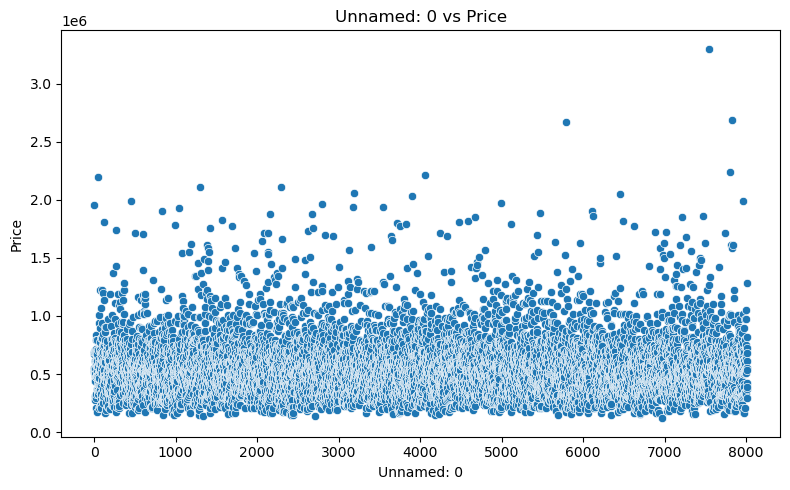

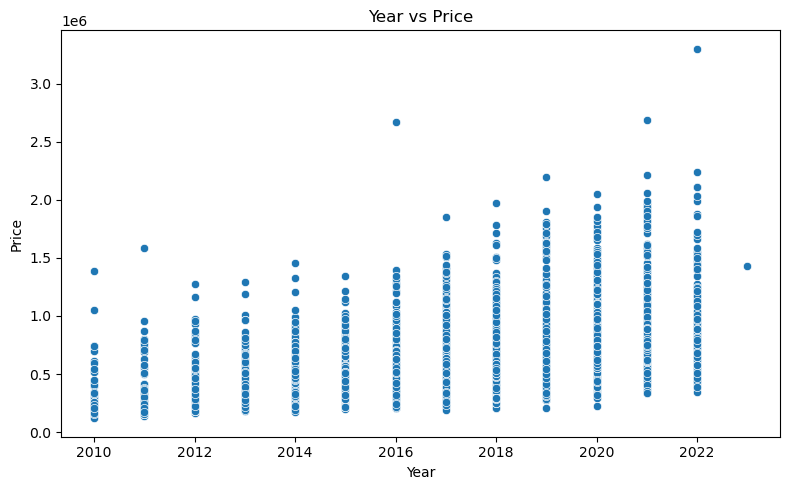

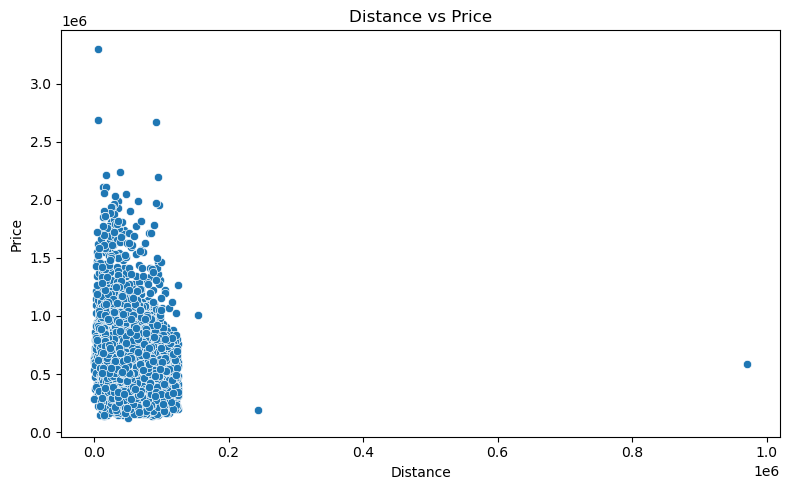

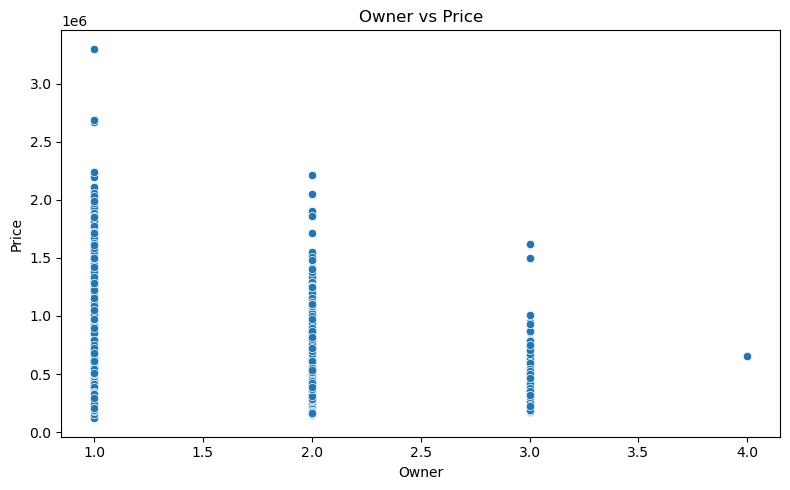

In [27]:
for col in numerical_columns:
    if col != 'Price':
        plt.figure(figsize=(8, 5))
        sns.scatterplot(data=df, x=col, y='Price')
        plt.title(f'{col} vs Price')
        plt.tight_layout()
        plt.show()

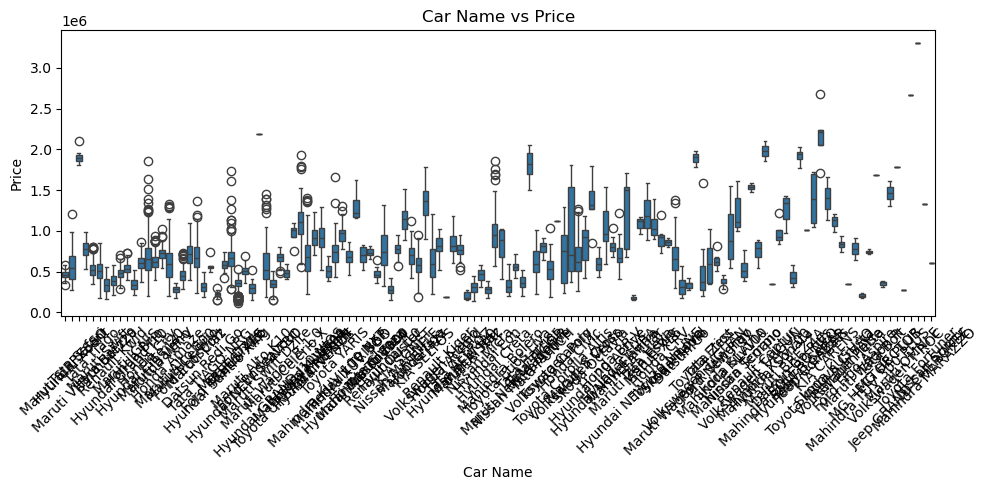

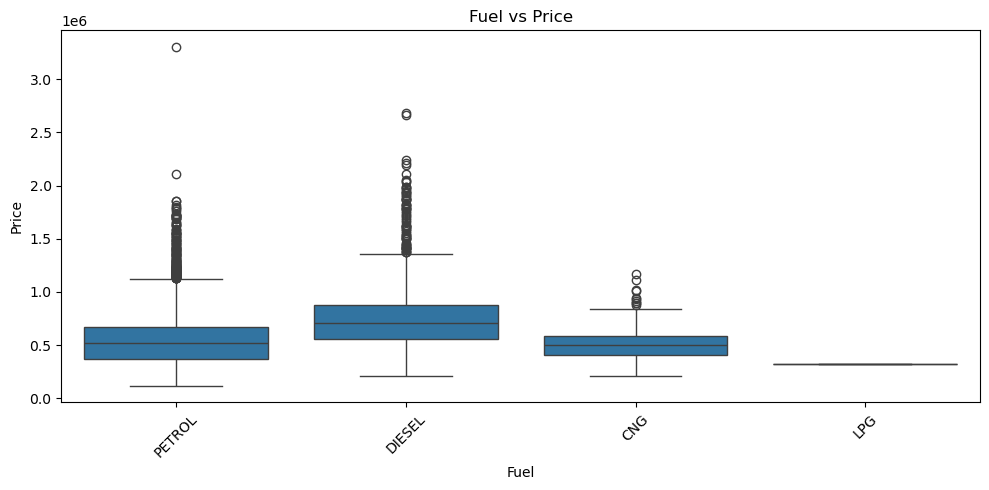

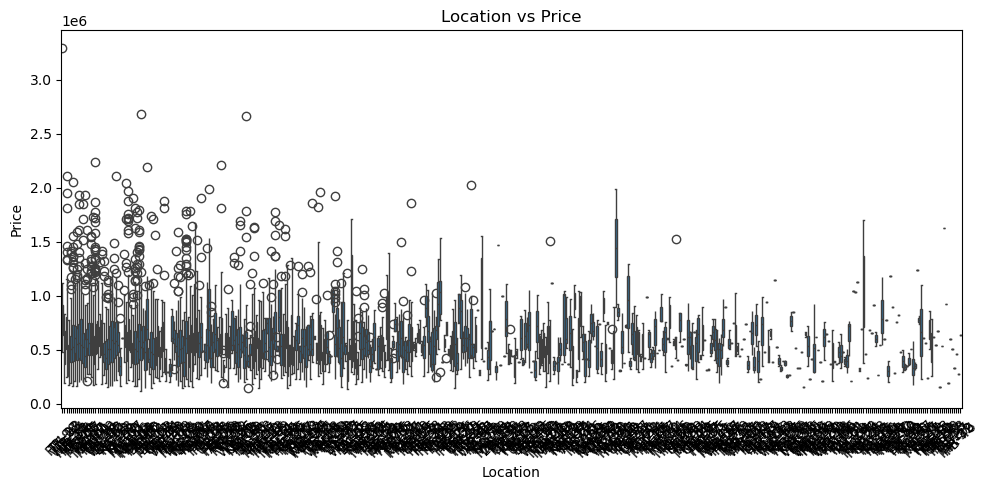

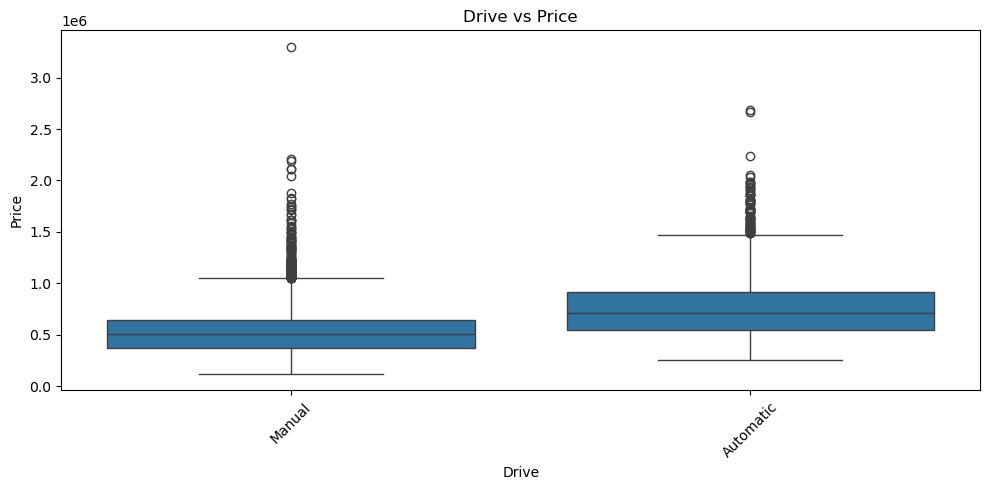

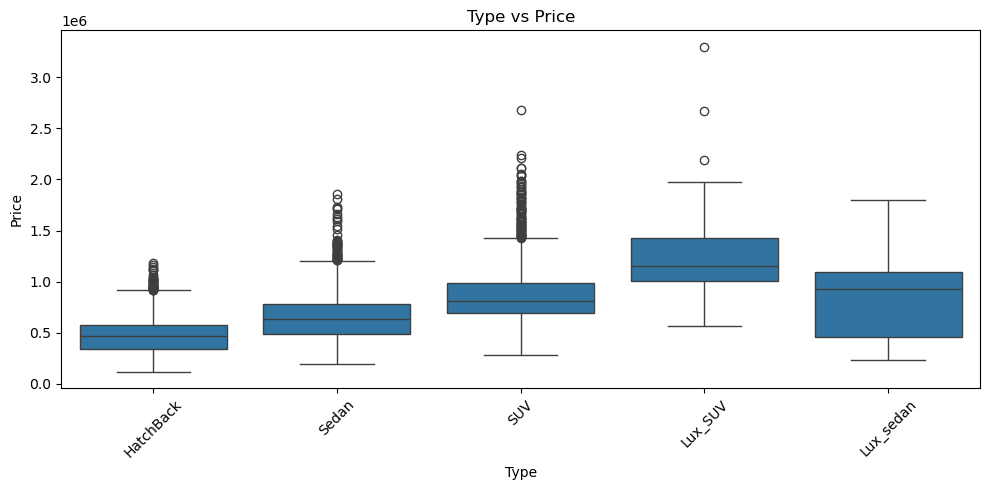

In [28]:
for col in categorical_columns:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df, x=col, y='Price')
    plt.title(f'{col} vs Price')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

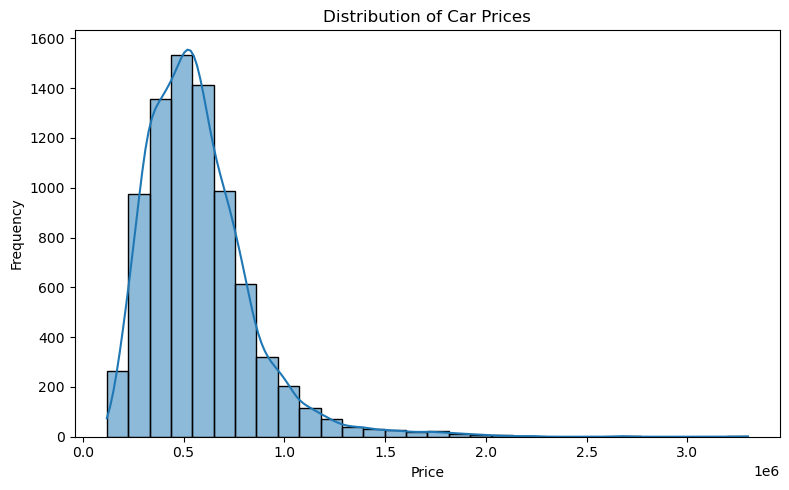

In [29]:
plt.figure(figsize=(8, 5))
sns.histplot(df['Price'], kde=True, bins=30)
plt.title('Distribution of Car Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

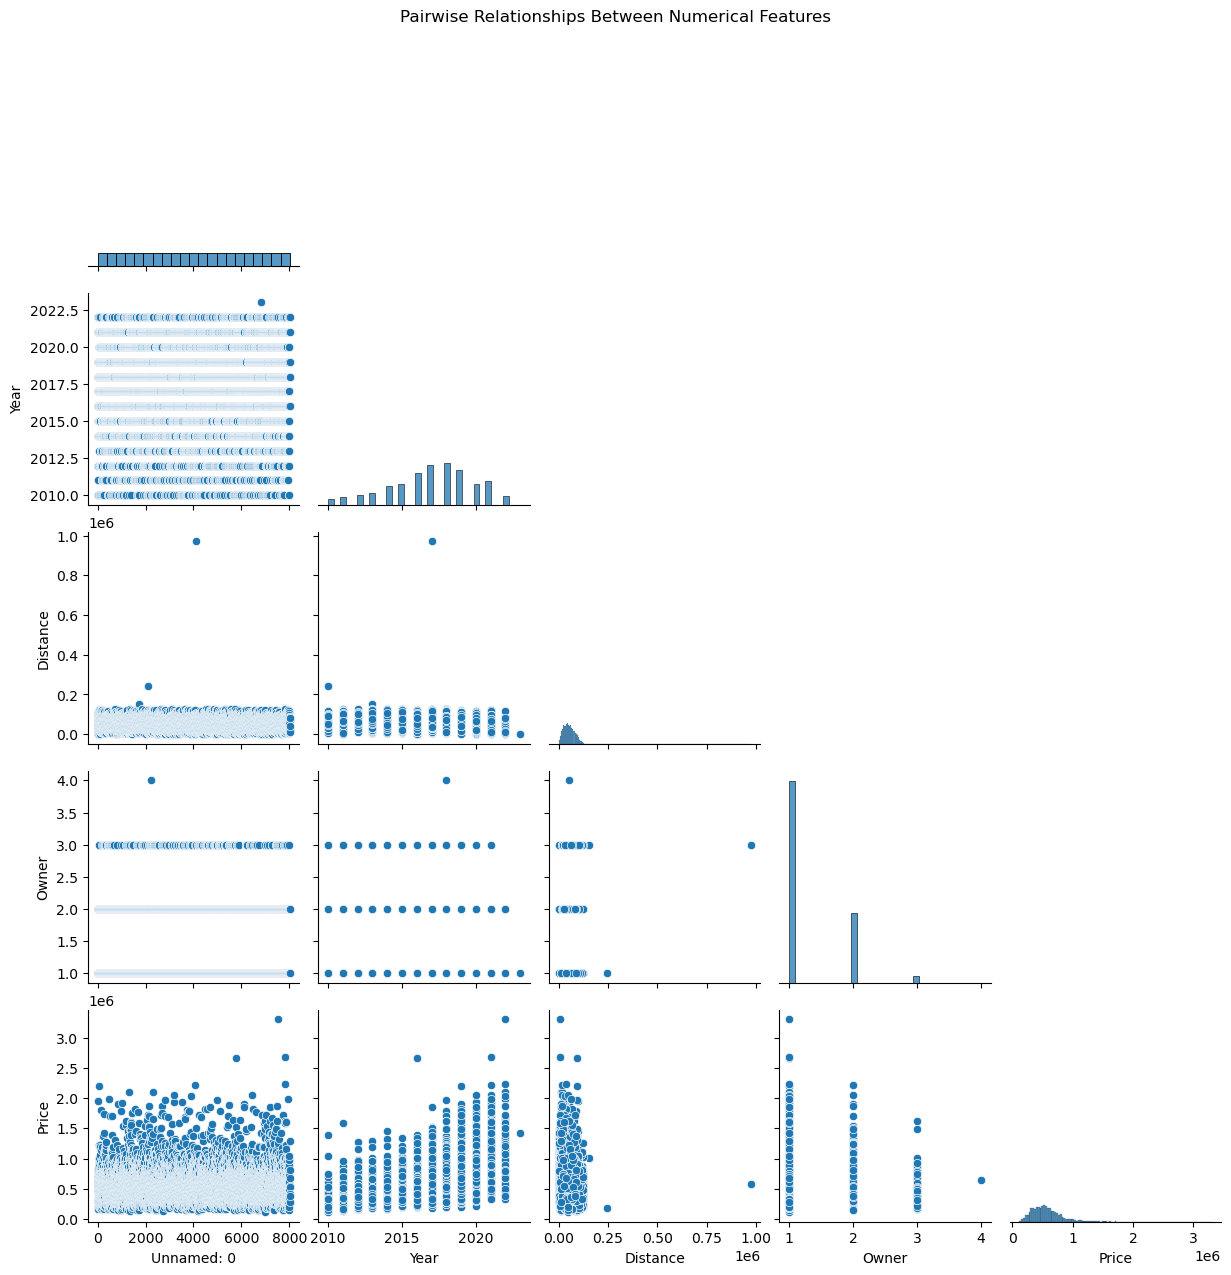

In [31]:
sns.pairplot(
    df[numerical_columns],
    diag_kind='hist',
    corner=True
)
plt.suptitle('Pairwise Relationships Between Numerical Features', y=1.02)
plt.show()

In [33]:
skewness = df[numerical_columns].skew()
print("Skewness of Numerical Features:")
print(skewness.sort_values(ascending=False))

Skewness of Numerical Features:
Distance      4.192015
Price         1.748487
Owner         1.437148
Unnamed: 0    0.000000
Year         -0.444533
dtype: float64


In [34]:
price_correlation = correlation['Price'].sort_values(ascending=False)
print("Correlation of Features with Price:")
print(price_correlation)

Correlation of Features with Price:
Price         1.000000
Year          0.501978
Unnamed: 0   -0.006814
Owner        -0.149925
Distance     -0.198950
Name: Price, dtype: float64


In [36]:
for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"{col}: {len(outliers)} outliers")

Unnamed: 0: 0 outliers
Year: 0 outliers
Distance: 3 outliers
Owner: 1 outliers
Price: 250 outliers


In [38]:
print("\nDataset Shape:", df.shape)
print("\nNumerical Features:", len(numerical_columns))
print("Categorical Features:", len(categorical_columns))
print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())
print("\nTarget Variable: Price")
print("Average Price:", df['Price'].mean())
print("Minimum Price:", df['Price'].min())
print("Maximum Price:", df['Price'].max())


Dataset Shape: (8015, 10)

Numerical Features: 5
Categorical Features: 5

Missing Values: 215
Duplicate Records: 0

Target Variable: Price
Average Price: 574882.8571428572
Minimum Price: 119000
Maximum Price: 3300000


In [41]:
print("Dataset contains", df.shape[0], "records and", df.shape[1], "features.")
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())
print(df[numerical_columns].describe().T)
print(price_correlation.drop('Price').abs().sort_values(ascending=False).head())
print(df['Price'].describe())

Dataset contains 8015 records and 10 features.
Missing Values: 215
Duplicate Records: 0
             count           mean            std       min       25%  \
Unnamed: 0  8015.0    4007.000000    2313.875537       0.0    2003.5   
Year        8014.0    2016.995009       2.861454    2010.0    2015.0   
Distance    8015.0   52621.411728   29182.922728       0.0   30730.0   
Owner       8015.0       1.300187       0.510893       1.0       1.0   
Price       8015.0  574882.857143  265104.875929  119000.0  393000.0   

                 50%       75%        max  
Unnamed: 0    4007.0    6010.5     8014.0  
Year          2017.0    2019.0     2023.0  
Distance     50359.0   71762.0   971212.0  
Owner            1.0       2.0        4.0  
Price       535000.0  698000.0  3300000.0  
Year          0.501978
Distance      0.198950
Owner         0.149925
Unnamed: 0    0.006814
Name: Price, dtype: float64
count    8.015000e+03
mean     5.748829e+05
std      2.651049e+05
min      1.190000e+05
25%    